# Actividad 4. Transformación del ingreso y auditoría de sesgos

Ignacio Agustin Costarelli - a2213

Analizo census_income.csv para predecir el ingreso anual, income, a partir de las características de cada persona. Comparo una regresión lineal sobre el ingreso original con otra sobre su logaritmo, usando validación cruzada.

Después elijo el modelo de menor MAE, reviso sus errores por sex y race y resumo los resultados en una Model Card.


In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path
from skops import card
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
N_FOLDS = 5

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)


## 1. Preparación de los datos

Cargo census_income.csv desde la misma carpeta que la notebook. Uso age y hours_per_week como variables numéricas. Trato education, employer_type, marital_status, sex, race y born_in_us como categóricas. La variable que quiero predecir es income.

Reviso los tipos de datos y los faltantes, y quito los espacios al principio y al final de los textos. Elimino las filas que coinciden en todas las columnas para evitar que una copia exacta quede en entrenamiento y otra en prueba. Como no tengo identificadores, no puedo confirmar si esas coincidencias son copias o personas distintas con los mismos datos.

Conservo los ingresos altos y completo los faltantes de las entradas dentro del modelo.


In [77]:
raw = pd.read_csv("census_income.csv", na_values=["?", "NA", "N/A"], skipinitialspace=True)
datos = raw.copy()

numericas = ["age", "hours_per_week"]
categoricas = ["education", "employer_type", "marital_status", "sex", "race", "born_in_us"]
target = "income"

for columna in categoricas:
    datos[columna] = datos[columna].str.strip().replace("", np.nan).astype(object)
datos[numericas + [target]] = datos[numericas + [target]].apply(pd.to_numeric)

duplicados = datos.duplicated().sum()
datos = datos.drop_duplicates().reset_index(drop=True)

print(f"Filas originales: {len(raw)}")
print(f"Filas repetidas que quito: {duplicados}")
print(f"Filas para el análisis: {len(datos)}")
display(pd.DataFrame({
    "tipo": datos.dtypes.astype(str),
    "faltantes": datos.isna().sum(),
    "faltantes_pct": 100 * datos.isna().mean(),
}))
display(datos.head())


Filas originales: 10000
Filas repetidas que quito: 86
Filas para el análisis: 9914


,tipo,faltantes,faltantes_pct
age,int64,0,0.000
hours_per_week,float64,499,5.033
education,object,300,3.026
employer_type,object,400,4.035
marital_status,object,0,0.000
sex,object,0,0.000
race,object,0,0.000
born_in_us,object,0,0.000
income,float64,0,0.000


,age,hours_per_week,education,employer_type,marital_status,sex,race,born_in_us,income
0,55,55.0,Graduate degree,Self-employed (incorporated),Divorced,Male,White,Yes,279000.0
1,20,35.0,High school,Private,Never married,Female,White,Yes,23000.0
2,59,30.0,High school,State government,Divorced,Female,White,Yes,15100.0
3,43,40.0,Some college,State government,Married,Male,Black,Yes,31200.0
4,33,20.0,No high school diploma,Private,Married,Female,Black,Yes,9400.0


De las 10.000 filas originales, quito 86 repeticiones exactas y trabajo con 9.914 registros. Encuentro faltantes en hours_per_week, education y employer_type. El ingreso no tiene faltantes. Mantengo esos registros y completo sus entradas durante el entrenamiento.


## 2. Separación de entrenamiento y prueba

Reservo el 20% para evaluar el modelo final. Con el 80% restante analizo la distribución del ingreso y comparo los modelos mediante cinco folds. Fijo la semilla en 42 y uso las mismas particiones para ambos modelos.

Incluyo la imputación, el escalado y la codificación dentro del pipeline. Así, en cada fold esos pasos se ajustan solo con los datos de entrenamiento. Dejo el conjunto de prueba fuera de la elección del modelo.

También considero qué información tendría al predecir. Uso income solo como objetivo y supongo que las ocho características de entrada ya están disponibles en ese momento. Antes de aplicar el modelo en otro contexto, tendría que confirmar esa disponibilidad.


In [78]:
X = datos[numericas + categoricas]
y = datos[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED,
)
cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train))

print(f"Entrenamiento y validación cruzada: {len(X_train)} filas")
print(f"Prueba final: {len(X_test)} filas")


Entrenamiento y validación cruzada: 7931 filas
Prueba final: 1983 filas


## 3. Distribución y transformación del ingreso

Parte 1, punto a.

Comparo el histograma y la asimetría de income con los de log(income), usando los datos de entrenamiento.

Elijo el logaritmo natural porque los ingresos son positivos y quiero reducir el peso de los valores más altos. Para volver a la escala original uso la exponencial. Box-Cox también requiere valores positivos y estima una potencia; Yeo-Johnson permite ceros y negativos, que no aparecen en estos datos.

Después comparo los modelos para ver si la transformación mejora el MAE. Una distribución más simétrica no asegura una mejor predicción.


,income,log(income)
mínimo,1.100e+02,4.700
mediana,3.690e+04,10.516
media,5.492e+04,10.355
percentil 95,1.522e+05,11.933
máximo,1.096e+06,13.907
skewness,4.409e+00,-1.005


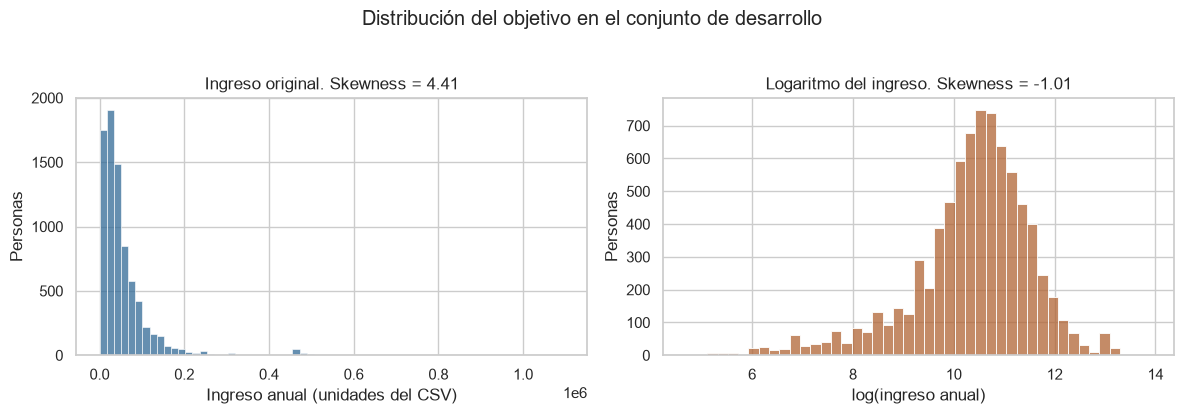

In [79]:
y_train_log = np.log(y_train)
resumen_target = pd.DataFrame({
    "income": [
        y_train.min(), y_train.median(), y_train.mean(), y_train.quantile(0.95),
        y_train.max(), y_train.skew(),
    ],
    "log(income)": [
        y_train_log.min(), y_train_log.median(), y_train_log.mean(),
        y_train_log.quantile(0.95), y_train_log.max(), y_train_log.skew(),
    ],
}, index=["mínimo", "mediana", "media", "percentil 95", "máximo", "skewness"])
display(resumen_target)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y_train, bins=65, ax=axes[0], color="#326a96")
axes[0].set(title=f"Ingreso original. Skewness = {y_train.skew():.2f}",
            xlabel="Ingreso anual (unidades del CSV)", ylabel="Personas")
sns.histplot(y_train_log, bins=45, ax=axes[1], color="#b16434")
axes[1].set(title=f"Logaritmo del ingreso. Skewness = {y_train_log.skew():.2f}",
            xlabel="log(ingreso anual)", ylabel="Personas")
fig.suptitle("Distribución del objetivo en el conjunto de desarrollo", y=1.03)
fig.tight_layout()
plt.show()


Observo una cola hacia los ingresos altos: la media es 54.916,4 y la mediana 36.900,0. La asimetría original es 4,409.

Con el logaritmo, la asimetría pasa a -1,005. La cola de ingresos altos se comprime y queda una asimetría hacia los valores bajos. La distribución es menos asimétrica, pero no se vuelve normal.


## 4. Regresión lineal con K-fold

Parte 1, punto b.

Completo los faltantes numéricos con la mediana, agrego un indicador de faltante y estandarizo. Para las variables categóricas uso Sin dato cuando falta el valor y codifico con one-hot, dejando una categoría de referencia.

Uso el mismo preprocesamiento en las dos regresiones. En el modelo logarítmico, TransformedTargetRegressor aplica el logaritmo al ingreso durante el ajuste y la exponencial al predecir. De esta forma, los errores de ambos modelos se calculan en la escala original del ingreso.


In [80]:
preprocesador = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median", add_indicator=True)),
        ("escalar", StandardScaler()),
    ]), numericas),
    ("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="constant", fill_value="Sin dato")),
        ("onehot", OneHotEncoder(
            drop="first", handle_unknown="ignore", sparse_output=False,
        )),
    ]), categoricas),
])

modelo_original = Pipeline([
    ("preprocesar", preprocesador),
    ("regresion", LinearRegression()),
])
modelo_log = TransformedTargetRegressor(
    regressor=clone(modelo_original), func=np.log, inverse_func=np.exp,
)
modelos = {"Lineal original": modelo_original, "Lineal log": modelo_log}
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}


In [81]:
filas_cv = []
for nombre, modelo in modelos.items():
    resultado = cross_validate(modelo, X_train, y_train, cv=folds, scoring=scoring)
    for k in range(N_FOLDS):
        filas_cv.append({
            "modelo": nombre,
            "fold": k + 1,
            "MAE": -resultado["test_MAE"][k],
            "RMSE": -resultado["test_RMSE"][k],
            "R2": resultado["test_R2"][k],
        })

detalle_cv = pd.DataFrame(filas_cv)
resumen_cv = detalle_cv.groupby("modelo").agg(
    MAE_medio=("MAE", "mean"), MAE_sd=("MAE", "std"),
    RMSE_medio=("RMSE", "mean"), R2_medio=("R2", "mean"),
).sort_values("MAE_medio")
display(detalle_cv)
display(resumen_cv)


,modelo,fold,MAE,RMSE,R2
0,Lineal original,1,32201.070,62177.576,0.280
1,Lineal original,2,32746.230,67144.820,0.272
2,Lineal original,3,30208.456,56925.432,0.250
3,Lineal original,4,30675.153,53014.566,0.280
4,Lineal original,5,31376.006,53537.286,0.222
5,Lineal log,1,30961.891,65167.075,0.209
6,Lineal log,2,31611.482,69216.287,0.227
7,Lineal log,3,28711.491,62733.624,0.090
8,Lineal log,4,28103.888,54973.852,0.226
9,Lineal log,5,28437.970,56606.039,0.130


,MAE_medio,MAE_sd,RMSE_medio,R2_medio
modelo,,,,
Lineal log,29565.344,1602.569,61739.376,0.176
Lineal original,31441.383,1047.764,58559.936,0.261


## 5. Comparación de MAE

Parte 1, punto c.

Elijo según el MAE promedio de validación cruzada. Reviso también su variación entre folds y uso RMSE y R² para complementar la comparación. Todos los errores corresponden al ingreso en su escala original.


Modelo elegido: Lineal log
Reducción del MAE con el logaritmo: 6.0%


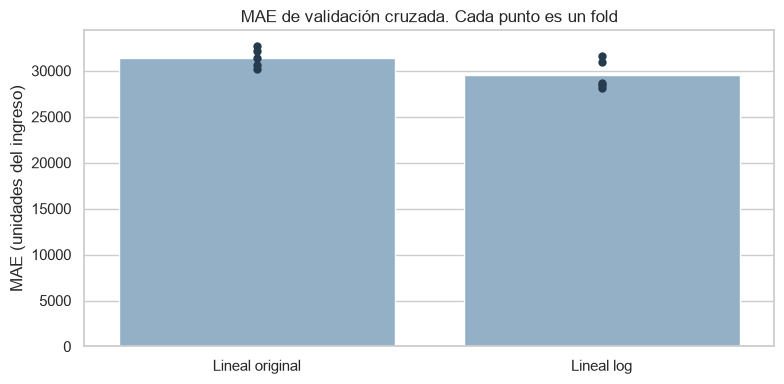

In [82]:
elegido = resumen_cv["MAE_medio"].idxmin()
mae_original = resumen_cv.loc["Lineal original", "MAE_medio"]
mae_log = resumen_cv.loc["Lineal log", "MAE_medio"]
mejora_pct = 100 * (mae_original - mae_log) / mae_original

print(f"Modelo elegido: {elegido}")
print(f"Reducción del MAE con el logaritmo: {mejora_pct:.1f}%")

fig, ax = plt.subplots(figsize=(8, 4))
orden = ["Lineal original", "Lineal log"]
sns.barplot(data=detalle_cv, x="modelo", y="MAE", order=orden,
            errorbar=None, color="#8ab1ce", ax=ax)
sns.stripplot(data=detalle_cv, x="modelo", y="MAE", order=orden,
              jitter=False, color="#263b4e", size=6, ax=ax)
ax.set(title="MAE de validación cruzada. Cada punto es un fold",
       xlabel="", ylabel="MAE (unidades del ingreso)")
fig.tight_layout()
plt.show()


Con el logaritmo, el MAE promedio baja de 31.441,4 a 29.565,3, una mejora del 6,0%. También obtengo un MAE menor en los cinco folds. Por eso elijo Lineal log.

La mejora depende de la métrica: el modelo original tiene menor RMSE, 58.559,9 frente a 61.739,4, y mayor R², 0,261 frente a 0,176.

La regresión minimiza errores cuadrados en la escala con la que la entreno. Al usar el logaritmo, comprimo las diferencias entre los ingresos altos antes del ajuste. Esto ayuda a interpretar por qué el MAE mejora mientras que el RMSE empeora en este caso. Uso el MAE para elegir el modelo, aunque el ajuste de la regresión siga usando errores cuadrados.


## 6. Evaluación del modelo final

Ajusto el modelo elegido con todo el conjunto de entrenamiento y predigo los ingresos de prueba. Calculo MAE, RMSE, R² y error medio.

Defino el error como predicción menos ingreso real. Un error medio negativo indica que, en promedio, el modelo estima ingresos menores a los reales. Uso estas predicciones para la auditoría por grupos.


In [83]:
modelo_final = clone(modelos[elegido]).fit(X_train, y_train)
pred_test = modelo_final.predict(X_test)

metricas_test = {
    "MAE": mean_absolute_error(y_test, pred_test),
    "RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
    "R2": r2_score(y_test, pred_test),
    "error_medio": np.mean(pred_test - y_test.to_numpy()),
}
display(pd.Series(metricas_test, name="Prueba").to_frame())

auditoria = X_test[["sex", "race"]].copy()
auditoria["real"] = y_test
auditoria["pred"] = pred_test
auditoria["error"] = auditoria["pred"] - auditoria["real"]
auditoria["error_abs"] = auditoria["error"].abs()


,Prueba
MAE,29448.891
RMSE,60954.437
R2,0.171
error_medio,-10000.729


En los 1.983 registros de prueba obtengo un MAE de 29.448,9, cercano al de validación cruzada. El RMSE es 60.954,4 y el R² es 0,171, por lo que la capacidad predictiva sigue siendo limitada.

El error medio es -10.000,7: en promedio, el modelo subestima los ingresos. La diferencia entre RMSE y MAE también muestra que hay errores grandes. Por eso no tomaría estas predicciones como estimaciones precisas para cada persona.


## 7. Auditoría por variables sensibles

Parte 2, punto a.

Como predigo un ingreso continuo, comparo el MAE y el error medio entre grupos. Reviso sex y race sobre las mismas predicciones de prueba, y muestro también la cantidad de casos y el ingreso medio de cada grupo.

Mantengo sex y race entre las entradas del modelo. Reviso tanto cuánto se equivoca como si tiende a estimar por encima o por debajo del ingreso real. Considero el tamaño de cada grupo y sus ingresos al interpretar las diferencias.


In [84]:
tablas_auditoria = {}
for columna in ["sex", "race"]:
    tablas_auditoria[columna] = auditoria.groupby(columna).agg(
        n=("real", "size"),
        ingreso_medio=("real", "mean"),
        MAE=("error_abs", "mean"),
        error_medio=("error", "mean"),
    )


### Resultados por sex


In [85]:
display(tablas_auditoria["sex"])


,n,ingreso_medio,MAE,error_medio
sex,,,,
Female,993,40993.917,21726.420,-7723.519
Male,990,66637.485,37194.764,-12284.840


Encuentro un MAE mayor en Male, 37.194,8, que en Female, 21.726,4. Los grupos tienen casi la misma cantidad de casos, 990 y 993, pero el ingreso medio es mayor en Male: 66.637,5 frente a 40.993,9.

El modelo subestima ambos grupos. El error medio es -12.284,8 en Male y -7.723,5 en Female. Hay una diferencia de desempeño, aunque parte de la diferencia de error absoluto puede estar relacionada con la escala del ingreso.


### Resultados por race


In [86]:
display(tablas_auditoria["race"])


,n,ingreso_medio,MAE,error_medio
race,,,,
Asian,88,50515.795,27575.648,-7481.440
Black,460,42020.000,20098.495,-8899.339
Other or multiple,83,32399.880,17876.446,3145.930
White,1352,59330.096,33462.605,-11346.521


White tiene el mayor MAE, 33.462,6, y Other or multiple el menor, 17.876,4. Asian y Black quedan en valores intermedios, con 27.575,6 y 20.098,5. Los ingresos medios también son distintos entre estos grupos.

Observo subestimación en White, Black y Asian. En Other or multiple el error medio es positivo, 3.145,9, por lo que el modelo sobreestima el ingreso en promedio. Interpreto con cuidado los resultados de Asian y Other or multiple porque tienen solo 88 y 83 casos.


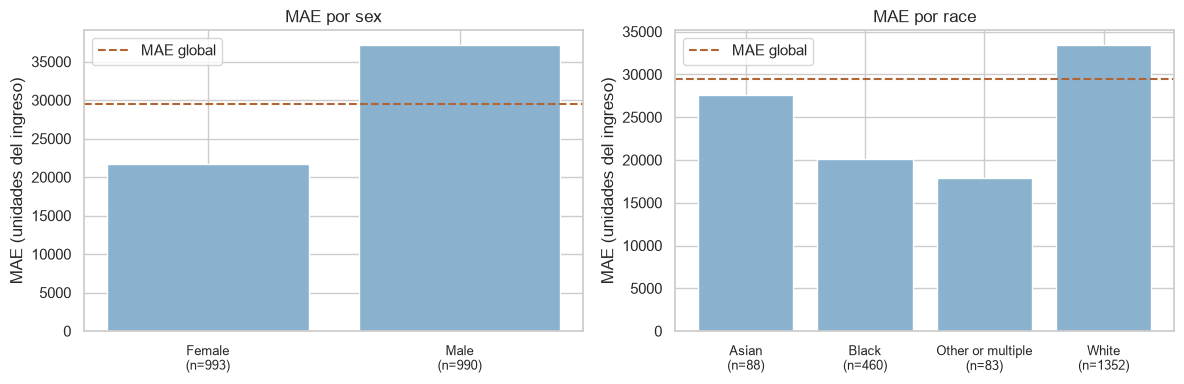

In [87]:
fig_auditoria, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (columna, tabla) in zip(axes, tablas_auditoria.items()):
    etiquetas = [f"{grupo}\n(n={n})" for grupo, n in zip(tabla.index, tabla["n"])]
    ax.bar(etiquetas, tabla["MAE"], color="#8ab1ce")
    ax.axhline(metricas_test["MAE"], color="#b16434", linestyle="--", label="MAE global")
    ax.set(title=f"MAE por {columna}", ylabel="MAE (unidades del ingreso)")
    ax.tick_params(axis="x", labelsize=9)
    ax.legend()
fig_auditoria.tight_layout()
plt.show()


Las tablas y los gráficos muestran que el modelo no tiene el mismo error en todos los grupos. Esto señala diferencias que tendría que revisar antes de usarlo. Por sí solas no demuestran discriminación causal ni permiten asegurar equidad: también influyen los ingresos, la cantidad de casos y la información disponible.

Tampoco asumiría que quitar sex y race elimina el problema, porque otras variables pueden compartir información con ellas. En esta actividad identifico las diferencias; para estudiar su origen necesitaría un análisis adicional.


### Importancia de las variables

Para completar la explicación del modelo, calculo la importancia por permutación sobre los datos de prueba. Mezclo una variable por vez y observo cuánto aumenta el MAE, sin volver a entrenar. Repito diez veces y tomo el promedio. Un aumento mayor indica que el modelo depende más de esa variable para predecir.


,aumento_MAE,desvio
hours_per_week,5679.935,371.269
education,5053.120,357.860
age,2762.432,464.200
employer_type,757.600,106.403
marital_status,527.993,110.733
sex,369.699,125.559
race,26.461,65.836
born_in_us,5.888,19.323


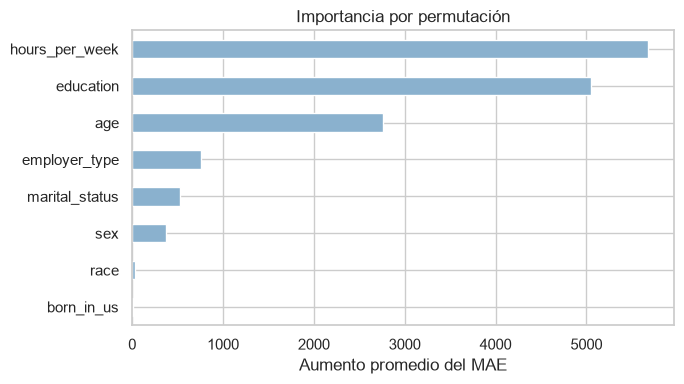

In [88]:
importancia = permutation_importance(
    modelo_final, X_test, y_test,
    scoring="neg_mean_absolute_error", n_repeats=10, random_state=SEED,
)
importancias = pd.DataFrame({
    "aumento_MAE": importancia.importances_mean,
    "desvio": importancia.importances_std,
}, index=X_test.columns).sort_values("aumento_MAE", ascending=False)
display(importancias)

fig_importancias, ax = plt.subplots(figsize=(7, 4))
importancias["aumento_MAE"].sort_values().plot.barh(ax=ax, color="#8ab1ce")
ax.set(title="Importancia por permutación",
       xlabel="Aumento promedio del MAE", ylabel="")
fig_importancias.tight_layout()
plt.show()


El MAE aumenta más al mezclar hours_per_week, 5.679,9, seguida por education, 5.053,1, y age, 2.762,4. Estas son las variables de las que más depende el modelo en esta prueba.

sex ocupa el sexto lugar, con un aumento de 369,7, y race el séptimo, con 26,5. En race, el aumento es pequeño frente al desvío de 65,8 entre repeticiones. Una importancia baja no demuestra equidad: otras variables pueden compartir esa información. Tampoco interpreto estas importancias como efectos causales ni como la dirección del cambio en el ingreso.


## 8. Model Card

Parte 2, punto b.

### 8.1. Detalles del modelo

- Nombre: estimación del ingreso anual.
- Versión: 1.0.
- Fecha: 16/10/2026.
- Responsable: Ignacio Agustin Costarelli, a2213.
- Tipo: regresión lineal sobre log(income), con inversión exponencial al predecir.

Uso age, hours_per_week, education, employer_type, marital_status, sex, race y born_in_us como entradas. Obtengo una estimación del ingreso anual en las mismas unidades de income.

### 8.2. Uso previsto y usos fuera de alcance

Uso el modelo para estimar ingresos y practicar la auditoría de sesgos en este ejercicio. Supongo que las características de entrada están disponibles al predecir.

No lo usaría como único criterio para fijar salarios o seleccionar personas. Tampoco lo aplicaría a otra población sin evaluarlo antes con datos de ese contexto.

### 8.3. Datos

Trabajo con census_income.csv, provisto para la actividad. De las 10.000 filas originales, quito 86 repeticiones exactas. Uso 7.931 registros para entrenamiento y validación cruzada, y 1.983 para prueba.

Completo los faltantes, escalo y codifico las variables dentro del pipeline. Comparo los modelos con cinco folds y semilla 42. Incluyo sex y race entre las entradas y también las uso para la auditoría.

### 8.4. Métricas de desempeño

Elijo el modelo por su MAE promedio de validación, que es 29.565,3. Después lo ajusto con todo el entrenamiento y obtengo estos resultados en prueba:

| Métrica | Valor |
|---|---:|
| MAE | 29.448,9 |
| RMSE | 60.954,4 |
| R² | 0,171 |
| Error medio | -10.000,7 |

### 8.5. Auditoría de sesgos

Comparo sex y race sobre las mismas predicciones de prueba. Calculo el error como predicción menos ingreso real.

| Variable | Grupo | Casos | MAE | Error medio |
|---|---|---:|---:|---:|
| sex | Female | 993 | 21.726,4 | -7.723,5 |
| sex | Male | 990 | 37.194,8 | -12.284,8 |
| race | Asian | 88 | 27.575,6 | -7.481,4 |
| race | Black | 460 | 20.098,5 | -8.899,3 |
| race | Other or multiple | 83 | 17.876,4 | 3.145,9 |
| race | White | 1.352 | 33.462,6 | -11.346,5 |

Encuentro mayor MAE en Male al comparar por sex y en White al comparar por race. El modelo subestima en promedio a todos los grupos salvo Other or multiple. Tengo en cuenta las diferencias de ingresos y tamaños al interpretar estos resultados.

### 8.6. Explicabilidad

Calculo importancia por permutación con diez repeticiones por variable. El MAE aumenta más al mezclar hours_per_week, 5.679,9, education, 5.053,1, y age, 2.762,4. sex ocupa el sexto lugar de ocho y race el séptimo. Estas importancias describen la dependencia del modelo y no demuestran causas ni equidad.

### 8.7. Limitaciones y riesgos

Los errores siguen siendo altos y algunos grupos tienen pocos casos. No tengo identificadores para comprobar independencia entre personas ni evalué otros períodos o poblaciones. Las diferencias de error y las importancias no demuestran discriminación causal ni garantizan equidad. Quitar una variable sensible tampoco asegura eliminar sus asociaciones con otras entradas.

### 8.8. Monitoreo

Si incorporara nuevos datos o volviera a entrenar, revisaría el MAE global y por sex y race, junto con la cantidad de casos de cada grupo. También compararía los faltantes y las distribuciones de las entradas para detectar cambios en la población.


### Archivo de la Model Card

Como complemento, uso skops para guardar una Model Card con esta misma estructura. Tomo las métricas, las tablas y los gráficos que calculé en la notebook. Escribo el uso previsto y las limitaciones, porque esa parte depende de cómo interpreto el problema.

In [89]:
carpeta_card = Path("model_card")
mc = card.Card(modelo_final, template=None, model_diagram=False)

mc.add(**{
    "Detalles del modelo": (
        "Nombre: estimación del ingreso anual. Versión: 1.0. Fecha: 16/10/2026.\n\n"
        "Responsable: Ignacio Agustin Costarelli, a2213.\n\n"
        f"Modelo elegido: {elegido}. Ajusto una regresión lineal sobre log(income) "
        "y aplico la exponencial al predecir.\n\n"
        f"Uso {', '.join(X_train.columns)} como entradas. Obtengo una estimación "
        "del ingreso anual en las mismas unidades de income."
    ),
    "Uso previsto y usos fuera de alcance": (
        "Uso el modelo para estimar ingresos y practicar la auditoría de sesgos "
        "en este ejercicio. Supongo que las entradas están disponibles al predecir. "
        "No lo usaría como único criterio para fijar salarios o seleccionar personas. "
        "Tampoco lo aplicaría a otra población sin evaluarlo antes."
    ),
    "Datos": (
        f"Trabajo con census_income.csv. De las {len(raw)} filas originales, "
        f"quito {duplicados} repeticiones exactas. Uso {len(X_train)} registros "
        f"para entrenamiento y validación, y {len(X_test)} para prueba.\n\n"
        "Completo los faltantes, escalo y codifico dentro del pipeline. "
        f"Comparo los modelos con {N_FOLDS} folds y semilla {SEED}. "
        "Incluyo sex y race entre las entradas y también las uso para la auditoría."
    ),
})
mc.add_metrics(
    section="Métricas de desempeño",
    description=(
        f"Elijo el modelo por su MAE promedio de validación: "
        f"{resumen_cv.loc[elegido, 'MAE_medio']:.1f}. "
        "Después lo ajusto con todo el entrenamiento y lo evalúo en prueba. "
        "Calculo el error como predicción menos ingreso real."
    ),
    **{nombre: round(valor, 3 if nombre == "R2" else 1)
       for nombre, valor in metricas_test.items()},
);


Agrego los resultados por grupo y la importancia por permutación. Guardo los gráficos junto al archivo para poder verlos al abrir la Model Card.

In [90]:
mc.add(**{
    "Auditoría de sesgos": (
        "Comparo sex y race sobre las mismas predicciones de prueba. "
        f"El mayor MAE por sex aparece en {tablas_auditoria['sex']['MAE'].idxmax()} "
        f"y por race en {tablas_auditoria['race']['MAE'].idxmax()}. "
        "Tengo en cuenta los ingresos y la cantidad de casos de cada grupo "
        "al interpretar las diferencias. Un error medio negativo indica subestimación."
    ),
})
for variable, tabla in tablas_auditoria.items():
    mc.add(**{
        f"Auditoría de sesgos/Resultados por {variable}":
            tabla.reset_index().round(1).to_markdown(index=False),
    })
fig_auditoria.savefig(carpeta_card / "auditoria_por_grupo.png", dpi=120)
mc.add_plot(**{"Auditoría de sesgos/Gráfico": "auditoria_por_grupo.png"})

mc.add(**{
    "Explicabilidad": (
        "Calculo importancia por permutación con diez repeticiones por variable, "
        "midiendo cuánto aumenta el MAE en prueba. Las variables con mayor "
        f"importancia son {', '.join(importancias.head(3).index)}. "
        "Esto describe la dependencia del modelo, sin demostrar causas ni equidad."
    ),
    "Explicabilidad/Importancias": (
        importancias.rename_axis("Variable").reset_index()
        .round(1).to_markdown(index=False)
    ),
})
fig_importancias.savefig(carpeta_card / "importancia_permutacion.png", dpi=120)
mc.add_plot(**{"Explicabilidad/Gráfico": "importancia_permutacion.png"});


Por último, agrego las limitaciones y qué revisaría si volviera a entrenar el modelo. Guardo el documento en la carpeta model_card.

In [91]:
mc.add(**{
    "Limitaciones y riesgos": (
        "Los errores siguen siendo altos y algunos grupos tienen pocos casos. "
        "No tengo identificadores para comprobar independencia entre personas "
        "ni evalué otros períodos o poblaciones. Las diferencias de error y las "
        "importancias no demuestran discriminación causal ni garantizan equidad. "
        "Quitar una variable sensible tampoco asegura eliminar sus asociaciones "
        "con otras entradas."
    ),
    "Monitoreo": (
        "Si incorporara nuevos datos o volviera a entrenar, revisaría el MAE global "
        "y por sex y race, junto con la cantidad de casos de cada grupo. También "
        "compararía los faltantes y las distribuciones de las entradas para detectar "
        "cambios en la población."
    ),
})
mc.save(carpeta_card / "README.md")
print("Model Card guardada en:", carpeta_card / "README.md")

Model Card guardada en: model_card\README.md


[Ver la Model Card generada](model_card/README.md).

## 9. Conclusiones

El logaritmo reduce la asimetría del ingreso y mejora el MAE de validación un 6,0%. Por eso elijo ese modelo, aunque la regresión sobre el ingreso original obtiene mejores valores de RMSE y R².

En prueba obtengo un MAE de 29.448,9 y un R² de 0,171. El resultado es parecido al de validación, pero todavía hay errores grandes y una tendencia a subestimar los ingresos.

Al revisar sex y race encuentro diferencias en el tamaño y la dirección de los errores. Los ingresos de cada grupo y la cantidad de casos ayudan a interpretar esas diferencias. La auditoría me permite identificar estas limitaciones, pero necesitaría más información y validación antes de usar el modelo para tomar decisiones sobre personas.
